In [1]:
import sys

sys.path.append("..")
import cupynumeric as np
from src.mixed_fps.simulate_quantization import NATIVE, FMT
from src.qm.hamsim import simulate_hamiltonian

[0 - 1fb7f9f00]    0.000000 {5}{module_config}: Module numa can not detect resources.


In [8]:
formats = NATIVE | FMT
formats.pop("fp64")
formats.pop("fp32")
formats

{'fp16': numpy.float16,
 'fp8_e4m3': {'exp_bits': 4, 'man_bits': 3, 'bias': 7},
 'fp8_e5m2': {'exp_bits': 5, 'man_bits': 2, 'bias': 15},
 'fp8_e3m4': {'exp_bits': 3, 'man_bits': 4, 'bias': 3},
 'fp8_e2m5': {'exp_bits': 2, 'man_bits': 5, 'bias': 1}}

In [36]:
n = 100
# generate random Hermitian components H1 and H2
A = np.random.randn(n, n) + 1j * np.random.randn(n, n)
B = np.random.randn(n, n) + 1j * np.random.randn(n, n)
H1 = (A + A.conj().T) / 2
H2 = (B + B.conj().T) / 2
H_terms = [H1, H2]

In [ ]:
errs = {}
errs2 = {}
errs3 = {}

In [ ]:
r = 100
t = 0.1

# initial state |ψ₀⟩ random normalized vector
psi = np.random.randn(n) + 1j * np.random.randn(n)
psi /= np.linalg.norm(psi)
psi_exact = np.linalg.expm(-1j * (H1 + H2) * t).dot(psi)


errs2 = {}
for fmt in formats:
    print(f"{fmt}")
    fmts = [fmt]
    # fmts = ["fp16"]
    # Rotate through mixed precisions: tiny + native
    # fmts = ["fp4_e2m1", "fp8_e4m3", "fp64", "fp8_e5m2"]
    # fmts = ["fp64"] * len(H_terms)  # all native fp64 for reference

    # psi_final, meta = simulate_hamiltonian(H_terms, psi, t, r, fmts, verbose=False, normalize=True)
    psi_final, meta = simulate_hamiltonian(
        H_terms,
        psi,
        t,
        r,
        fmt_list=fmts,  # native 64-bit
        compute_dtype=np.float32,  # feed 64-bit into solver
        work_dtype=np.float32,  # eigensolver in 64-bit
        out_dtype=np.complex64,  # output complex 64-bit
        verbose=False,
    )
    # normalize final state
    psi_final /= np.linalg.norm(psi_final)

    err = np.linalg.norm(psi_exact - psi_final)
    errs2[fmt] = err

fp16
fp8_e4m3
fp8_e5m2
fp8_e3m4
fp8_e2m5


In [40]:
mantissa_memory = {
    "fp8_e4m3": 0.375,
    "fp8_e5m2": 0.25,
    "fp8_e3m4": 0.5,
    "fp8_e2m5": 0.625,
    "fp16": 1.25,
    "fp32": 2.875,
    "fp64": 6.5,
}

Text(0, 0.5, 'Trotter error')

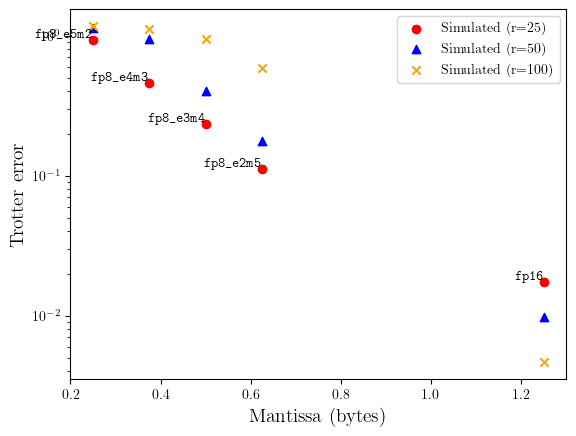

In [42]:
import matplotlib.pyplot as plt

# use latex
plt.rc("text", usetex=True)
plt.rc("font", family="serif")


# plt.figure(figsize=(8,5))
plt.scatter(
    [mantissa_memory[fmt] for fmt in errs3.keys()],
    [errs3[fmt] for fmt in errs3.keys()],
    label="Simulated (r=25)",
    marker="o",
    c="red",
)
plt.scatter(
    [mantissa_memory[fmt] for fmt in errs.keys()],
    [errs[fmt] for fmt in errs.keys()],
    label="Simulated (r=50)",
    marker="^",
    c="blue",
)
plt.scatter(
    [mantissa_memory[fmt] for fmt in errs2.keys()],
    [errs2[fmt] for fmt in errs2.keys()],
    label="Simulated (r=100)",
    marker="x",
    c="orange",
)
for fmt in errs.keys():
    plt.text(
        mantissa_memory[fmt],
        errs3[fmt],
        f"$\\texttt{{{fmt}}}$",
        fontsize=10,
        ha="right",
        va="bottom",
    )
    # plt.text(mantissa_memory[fmt], errs2[fmt], f"$\\texttt{{{fmt}}}$", fontsize=10, ha='left', va='bottom')

plt.legend()
plt.yscale("log")
plt.xlabel("Mantissa (bytes)", fontsize=14)
plt.ylabel("Trotter error", fontsize=14)

In [13]:
np.linalg.norm(psi_final)

array(1., dtype=float32)

In [14]:
n = 10
# generate random Hermitian components H1 and H2
A = np.random.randn(n, n) + 1j * np.random.randn(n, n)
B = np.random.randn(n, n) + 1j * np.random.randn(n, n)
H1 = (A + A.conj().T) / 2
H2 = (B + B.conj().T) / 2
H_terms = [H1, H2]

psi = np.random.randn(n) + 1j * np.random.randn(n)
psi /= np.linalg.norm(psi)

In [15]:
import cupynumeric as np

...

t = 0.4
r = 6

fmts = ["fp16", "fp32", "fp8_e4m3"]

psi_final = simulate_hamiltonian(H_terms, psi, t, r, fmts, verbose=True, normalize=True)
psi_exact = np.linalg.expm(-1j * (H1 + H2) * t).dot(psi)
print("Approx error:", np.linalg.norm(psi_exact - psi_final))

Step 0, format start: fp16
Step 1, format start: fp32
Step 2, format start: fp8_e4m3
Step 3, format start: fp16
Step 4, format start: fp32
Step 5, format start: fp8_e4m3


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (2,) + inhomogeneous part.